In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import confusion_matrix
from imblearn.metrics import classification_report_imbalanced

In [ ]:
#Reading Data

file_path = Path("data/LoanStats_2019Q1.zip")

df = pd.read_csv(file_path)

df.head()


,loan_amnt,int_rate,installment,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,dti,...,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,hardship_flag,debt_settlement_flag
0,10500.0,0.1719,375.35,RENT,66000.0,Source Verified,Mar-2019,low_risk,n,27.24,...,85.7,100.0,0.0,0.0,65687.0,38199.0,2000.0,61987.0,N,N
1,25000.0,0.2000,929.09,MORTGAGE,105000.0,Verified,Mar-2019,low_risk,n,20.23,...,91.2,50.0,1.0,0.0,271427.0,60641.0,41200.0,49197.0,N,N
2,20000.0,0.2000,529.88,MORTGAGE,56000.0,Verified,Mar-2019,low_risk,n,24.26,...,66.7,50.0,0.0,0.0,60644.0,45684.0,7500.0,43144.0,N,N
3,10000.0,0.1640,353.55,RENT,92000.0,Verified,Mar-2019,low_risk,n,31.44,...,100.0,50.0,1.0,0.0,99506.0,68784.0,19700.0,76506.0,N,N
4,22000.0,0.1474,520.39,MORTGAGE,52000.0,Not Verified,Mar-2019,low_risk,n,18.76,...,100.0,0.0,0.0,0.0,219750.0,25919.0,27600.0,20000.0,N,N


<Axes: ylabel='verification_status'>

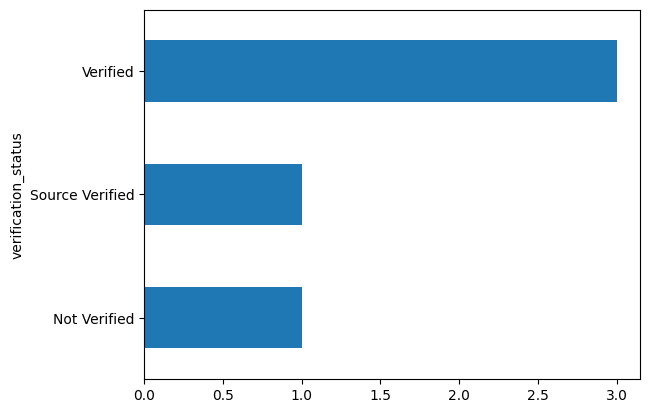

In [ ]:
df.groupby('verification_status').size().plot(kind='barh')

In [ ]:
#We need to clean up our data before analyzing to avoid errors

df = df.dropna() #dropping null data

df['int_rate'] = df['int_rate'].str.replace('%') #Converting

df['int_rate'] = df['int_rate'].astype('float')/100 #Converting

In [ ]:
#Creating Features

x = df.drop(columns = 'loan_status')
x = pd.get_dummies(x) #Another copy of the file

#Creating Target
target = ["loan_status"]

y = df.loc[:,target].copy()

x.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
count,68817.000000,68817.000000,68817.000000,6.881700e+04,68817.000000,68817.000000,68817.000000,68817.000000,68817.000000,68817.000000,...,68817.000000,68817.000000,68817.000000,68817.000000,68817.000000,68817.0,6.881700e+04,6.881700e+04,68817.000000,6.881700e+04
mean,16677.594562,0.127718,480.652863,8.821371e+04,21.778153,0.217766,0.497697,12.587340,0.126030,17604.142828,...,0.052138,2.219423,95.057627,30.626217,0.125972,0.0,2.100332e+05,6.133843e+04,29734.128558,5.572240e+04
std,10277.348590,0.048130,288.062432,1.155800e+05,20.199244,0.718367,0.758122,6.022869,0.336797,21835.880400,...,0.390633,1.897432,8.326426,33.631463,0.336732,0.0,1.928088e+05,5.738798e+04,26795.394232,5.095845e+04
min,1000.000000,0.060000,30.890000,4.000000e+01,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,20.000000,0.000000,0.000000,0.0,3.600000e+03,2.350000e+02,100.000000,1.270000e+02
25%,9000.000000,0.088100,265.730000,5.000000e+04,13.890000,0.000000,0.000000,8.000000,0.000000,6293.000000,...,0.000000,1.000000,93.000000,0.000000,0.000000,0.0,6.697700e+04,2.650300e+04,11600.000000,2.288000e+04
50%,15000.000000,0.118000,404.560000,7.300000e+04,19.760000,0.000000,0.000000,11.000000,0.000000,12068.000000,...,0.000000,2.000000,100.000000,20.000000,0.000000,0.0,1.467100e+05,4.535700e+04,22100.000000,4.200000e+04
75%,24000.000000,0.155700,648.100000,1.040000e+05,26.660000,0.000000,1.000000,16.000000,0.000000,21735.000000,...,0.000000,3.000000,100.000000,50.000000,0.000000,0.0,3.036400e+05,7.657000e+04,39300.000000,7.249900e+04
max,40000.000000,0.308400,1676.230000,8.797500e+06,999.000000,18.000000,5.000000,72.000000,4.000000,587191.000000,...,18.000000,19.000000,100.000000,100.000000,4.000000,0.0,3.292782e+06,1.295455e+06,509400.000000,1.426964e+06


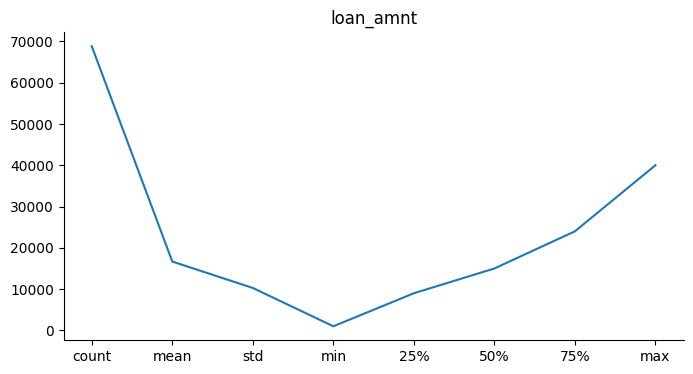

In [ ]:
df['loan_amnt'].plot(kind='line', figsize=(8, 4), title='loan_amnt')

In [ ]:
#Cheking the balance of our target
y['loan_status'].value_counts()

,count
loan_status,
low_risk,68470
high_risk,347


<Axes: ylabel='loan_status'>

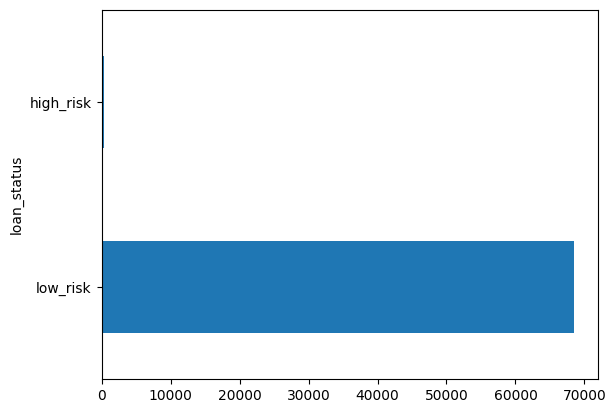

In [44]:
y['loan_status'].value_counts().plot(kind='barh')

In [ ]:
#Training our data
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x , y , random_state=1)

In [ ]:
#Pre Processing The Data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [ ]:
x_scaler = scaler.fit(x_train)

In [ ]:
#Applying scale and train our data

x_train_scaled = x_scaler.transform(x_train)
x_test_scaled = x_scaler.transform(x_test)

In [ ]:
#Learn

from imblearn.ensemble import BalancedRandomForestClassifier

brf = BalancedRandomForestClassifier(n_estimators=100 , random_state=1)
brf.fit(x_train_scaled , y_train)

BalancedRandomForestClassifier(random_state=1)

In [ ]:
y_pred = brf.predict(x_test_scaled)
balanced_accuracy_score(y_test , y_pred)

0.7887512850910909

In [ ]:
confusion_matrix(y_test , y_pred)

array([[   71,    30],
       [ 2146, 14958]])

In [ ]:
print(classification_report_imbalanced(y_test , y_pred))

                   pre       rec       spe        f1       geo       iba       sup

  high_risk       0.03      0.70      0.87      0.06      0.78      0.60       101
   low_risk       1.00      0.87      0.70      0.93      0.78      0.63     17104

avg / total       0.99      0.87      0.70      0.93      0.78      0.63     17205



In [ ]:
#Listing the features stored (descending)

importances = brf.feature_importances_

indicate = np.argsort(importances)[::-1]
for f in range(x.shape[1]):
    print(f"{x.columns.values[indicate[f]]}: ({importances[indicate[f]]})")

total_rec_prncp: (0.07876809003486353)
total_pymnt: (0.05883806887524815)
total_pymnt_inv: (0.05625613759225244)
total_rec_int: (0.05355513093134745)
last_pymnt_amnt: (0.0500331813446525)
int_rate: (0.02966959508700077)
issue_d_Jan-2019: (0.021129125328012987)
installment: (0.01980242888931366)
dti: (0.01747062730041245)
out_prncp_inv: (0.016858293184471483)
total_bal_ex_mort: (0.01641297102011915)
mths_since_recent_inq: (0.015220714904737209)
issue_d_Mar-2019: (0.015115240704562424)
revol_bal: (0.014926655663448373)
max_bal_bc: (0.014899352873994727)
out_prncp: (0.014881069023035237)
mo_sin_old_rev_tl_op: (0.014859446582326507)
annual_inc: (0.014832564501144122)
bc_util: (0.014613819728800227)
tot_hi_cred_lim: (0.014487685026878092)
mo_sin_old_il_acct: (0.013921085423763812)
mths_since_rcnt_il: (0.013534131593418711)
total_rev_hi_lim: (0.013364759441576994)
avg_cur_bal: (0.01332289882475225)
bc_open_to_buy: (0.013265926832893358)
il_util: (0.01311545089813887)
total_bc_limit: (0.01304

In [ ]:
#Easy Classification (Ensemble Classifier)

from imblearn.ensemble import EasyEnsembleClassifier

eec = EasyEnsembleClassifier(n_estimators = 100 , random_state =1)
eec.fit(x_train_scaled , y_train)

EasyEnsembleClassifier(n_estimators=100, random_state=1)

In [ ]:
#Calculating Balance Accuracy

y_pred = eec.predict(x_test_scaled)

balanced_accuracy_score(y_test , y_pred)

0.8724497888282747

In [ ]:
#Confusion Matrix

confusion_matrix(y_test , y_pred)

print(classification_report_imbalanced(y_test ,y_pred))

                   pre       rec       spe        f1       geo       iba       sup

  high_risk       0.06      0.82      0.92      0.11      0.87      0.75       101
   low_risk       1.00      0.92      0.82      0.96      0.87      0.77     17104

avg / total       0.99      0.92      0.82      0.95      0.87      0.77     17205

